# S2 — profile: news (Chronicling America 1770–1810)
Read-only profile of `data/raw/news/*.parquet` (6 shards, one row = one newspaper **page**). Task: `tasks/T-001-s2-profile-news.md`. Caveats: `docs/DATA.md`.
Method: DuckDB SQL over the raw parquet; nothing is written to `data/`. No ML/LLM used (regex only).
Source: `loc_chronicling_america_1770-1810`, revision `0b97906a…` (see `data/raw/MANIFEST.md`).

In [1]:
import duckdb, pandas as pd
from pathlib import Path
pd.set_option('display.width',200); pd.set_option('display.max_rows',80); pd.set_option('display.max_colwidth',90)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data'/'raw').exists())
NEWS=str(ROOT/'data/raw/news/*.parquet')
con=duckdb.connect()
con.sql(f"create view news as select *, year(issue_date) yr, length(RevX_OCR_text) len_rx, length(ca_ocr_text) len_ca from read_parquet('{NEWS}', filename=true)")
q=lambda s: con.sql(s).df()
q("select count(*) rows, count(distinct lccn) lccns, count(distinct newspaper_title) titles, count(distinct place_of_publication) places, count(distinct (lccn,issue_date,edition_order)) issues from news")

,rows,lccns,titles,places,issues
0,77793,110,105,48,19445


## 1. Rows and nulls

In [2]:
cols=['lccn','newspaper_title','place_of_publication','issue_date','edition_order','Page','RevX_OCR_text','ca_ocr_text']
nulls=q("select "+",".join(f"sum(({c} is null)::int) {c}" for c in cols)+" from news").T
nulls.columns=['null']; nulls['empty_or_blank']=q("select "+",".join(f"sum(({c} is not null and trim({c})='')::int) {c}" for c in ['RevX_OCR_text','ca_ocr_text'])+" from news").T.reindex(nulls.index)[0]
nulls


,null,empty_or_blank
lccn,0.0,NaN
newspaper_title,0.0,NaN
place_of_publication,0.0,NaN
issue_date,0.0,NaN
edition_order,0.0,NaN
Page,0.0,NaN
RevX_OCR_text,266.0,1216.0
ca_ocr_text,0.0,6.0


In [3]:
q('select filename, count(*) rows, min(issue_date)::date mn, max(issue_date)::date mx from news group by 1 order by 1')

,filename,rows,mn,mx
0,/Users/larawashington/Documents/Parsons/MajorStudio1/Projects/revolutionary-xroads/dat...,12966,1770-08-23,1810-12-31
1,/Users/larawashington/Documents/Parsons/MajorStudio1/Projects/revolutionary-xroads/dat...,12966,1770-01-05,1810-12-31
2,/Users/larawashington/Documents/Parsons/MajorStudio1/Projects/revolutionary-xroads/dat...,12966,1775-01-02,1802-12-22
3,/Users/larawashington/Documents/Parsons/MajorStudio1/Projects/revolutionary-xroads/dat...,12965,1778-02-24,1809-12-29
4,/Users/larawashington/Documents/Parsons/MajorStudio1/Projects/revolutionary-xroads/dat...,12965,1770-02-15,1810-12-31
5,/Users/larawashington/Documents/Parsons/MajorStudio1/Projects/revolutionary-xroads/dat...,12965,1770-01-25,1810-12-31


## 2. Dates by year

,yr,pages,issues,titles
0,1770,448,113,4
1,1771,546,136,4
2,1772,675,171,6
3,1773,846,209,6
4,1774,1205,284,8
5,1775,1286,294,7
6,1776,2319,537,16
7,1777,1320,315,11
8,1778,970,250,11
9,1779,1660,415,9


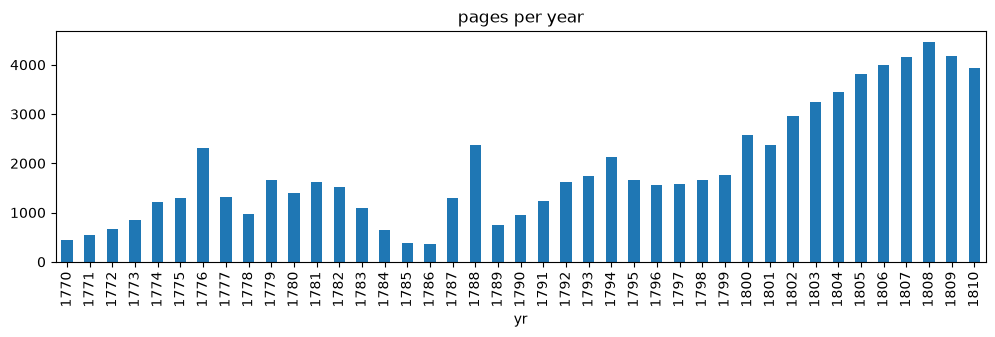

In [4]:
by_year=q("select yr, count(*) pages, count(distinct (lccn,issue_date,edition_order)) issues, count(distinct lccn) titles from news group by 1 order by 1")
display(by_year)
by_year.set_index('yr')['pages'].plot(kind='bar',figsize=(12,3),title='pages per year');

In [5]:
print('range', q('select min(issue_date)::date a, max(issue_date)::date b from news').iloc[0].tolist())
q("select yr, count(*) pages from news where yr between 1770 and 1774 group by 1 order by 1").assign(note='DATA.md says ~2,600 pages 1770-74')

range [Timestamp('1770-01-05 00:00:00'), Timestamp('1810-12-31 00:00:00')]


,yr,pages,note
0,1770,448,"DATA.md says ~2,600 pages 1770-74"
1,1771,546,"DATA.md says ~2,600 pages 1770-74"
2,1772,675,"DATA.md says ~2,600 pages 1770-74"
3,1773,846,"DATA.md says ~2,600 pages 1770-74"
4,1774,1205,"DATA.md says ~2,600 pages 1770-74"


## 3. Titles and places

In [6]:
tp=q("select lccn, any_value(newspaper_title) title, count(distinct newspaper_title) n_title_variants, any_value(place_of_publication) place, count(distinct place_of_publication) n_place_variants, min(yr) first_yr, max(yr) last_yr, count(*) pages from news group by 1 order by pages desc")
print(len(tp),'lccns'); tp.head(25)

110 lccns


,lccn,title,n_title_variants,place,n_place_variants,first_yr,last_yr,pages
0,sn83045242,The national intelligencer and Washington advertiser.,1,Washington City [D.C.],1,1800,1809,5575
1,sn84024012,Alexandria daily advertiser,1,Alexandria [Va.],1,1803,1808,4345
2,sn85025815,Norfolk gazette and publick ledger,1,Norfolk [Va.],1,1804,1810,3900
3,sn83025588,The New Hampshire gazette,1,Portsmouth [N.H.],1,1793,1810,3710
4,sn83025881,"Gazette of the United States, & Philadelphia daily advertiser.",1,Philadelphia [Pa.],1,1796,1800,3553
5,sn84024710,Virginia Argus,1,"Richmond, Va.",1,1797,1810,3216
6,sn84024736,The enquirer,1,"Richmond, Va.",1,1804,1810,2997
7,sn84024013,"Alexandria daily gazette, commercial & political",1,Alexandria [Va.],1,1808,1810,2934
8,sn83021127,"The Pennsylvania packet, or, The general advertiser",1,"Lancaster, Pa.;Philadelphia, Pa.",1,1777,1783,2893
9,sn82014782,The Kentucky gazette,1,Lexington [Ky.],1,1789,1803,2649


In [7]:
pl=q("select place_of_publication place, count(*) pages, count(distinct lccn) lccns from news group by 1 order by pages desc")
print(len(pl),'place strings'); pl.head(25)

48 place strings


,place,pages,lccns
0,Alexandria [Va.],9459,3
1,Philadelphia [Pa.],7268,6
2,"Richmond, Va.",6532,4
3,Washington City [D.C.],5575,1
4,Portsmouth [N.H.],5532,3
5,New-York [N.Y.],4153,6
6,Norfolk [Va.],3900,1
7,"Portsmouth, N.H.",3862,8
8,Lexington [Ky.],3773,3
9,"Lancaster, Pa.;Philadelphia, Pa.",2893,1


In [8]:
# multi-variant check
tp[(tp.n_title_variants>1)|(tp.n_place_variants>1)].head(15)

,lccn,title,n_title_variants,place,n_place_variants,first_yr,last_yr,pages


In [9]:
# state suffix (after last comma) as rough geography
st=q("select regexp_extract(place_of_publication,'([^,]+)$',1) state_part, count(*) pages from news group by 1 order by 2 desc"); st.head(15)

,state_part,pages
0,Alexandria [Va.],9459
1,Va.,9018
2,Philadelphia [Pa.],7268
3,N.H.,6581
4,Washington City [D.C.],5575
5,Portsmouth [N.H.],5532
6,Pa.,4940
7,New-York [N.Y.],4153
8,Norfolk [Va.],3900
9,Lexington [Ky.],3773


## 4. OCR source mix — `RevX_OCR_text` vs `ca_ocr_text`

In [10]:
q("select count(*) pages, sum((RevX_OCR_text is not null and trim(RevX_OCR_text)<>'')::int) has_revx, sum((ca_ocr_text is not null and trim(ca_ocr_text)<>'')::int) has_ca, sum(((RevX_OCR_text is not null and trim(RevX_OCR_text)<>'') and (ca_ocr_text is not null and trim(ca_ocr_text)<>''))::int) has_both, sum(((coalesce(trim(RevX_OCR_text),'')='') and (coalesce(trim(ca_ocr_text),'')=''))::int) has_neither from news")

,pages,has_revx,has_ca,has_both,has_neither
0,77793,76311.0,77787.0,76305.0,0.0


In [11]:
mix=q("""select yr, count(*) pages,
 round(100*avg((coalesce(trim(RevX_OCR_text),'')<>'')::int),1) pct_revx,
 round(100*avg((coalesce(trim(ca_ocr_text),'')<>'')::int),1) pct_ca,
 round(median(len_rx)) med_len_revx, round(median(len_ca)) med_len_ca
 from news group by 1 order by 1"""); mix

,yr,pages,pct_revx,pct_ca,med_len_revx,med_len_ca
0,1770,448,98.7,100.0,13830.0,13532.0
1,1771,546,98.4,100.0,15752.0,16045.0
2,1772,675,99.4,100.0,14941.0,15328.0
3,1773,846,98.7,100.0,15915.0,16562.0
4,1774,1205,97.9,100.0,18552.0,19750.0
5,1775,1286,99.4,100.0,15649.0,17340.0
6,1776,2319,99.7,100.0,10488.0,11382.0
7,1777,1320,99.5,100.0,10342.0,10948.0
8,1778,970,99.0,100.0,12902.0,13289.0
9,1779,1660,99.5,100.0,13691.0,14341.0


In [12]:
q("""select round(median(len_rx::double/nullif(len_ca,0)),2) median_ratio_revx_over_ca,
 round(quantile_cont(len_rx::double/nullif(len_ca,0),0.05),2) p05, round(quantile_cont(len_rx::double/nullif(len_ca,0),0.95),2) p95 from news""")

,median_ratio_revx_over_ca,p05,p95
0,0.98,0.53,1.14


## 5. Text length

In [13]:
q("select 'RevX' src, count(len_rx) n, min(len_rx) mn, quantile_cont(len_rx,.05) p05, median(len_rx) med, quantile_cont(len_rx,.95) p95, max(len_rx) mx, sum(len_rx)/1e6 mchars from news union all select 'ca', count(len_ca), min(len_ca), quantile_cont(len_ca,.05), median(len_ca), quantile_cont(len_ca,.95), max(len_ca), sum(len_ca)/1e6 from news")

,src,n,mn,p05,med,p95,mx,mchars
0,RevX,77527,0,6792.3,16951.0,28382.0,49042,1348.732802
1,ca,77793,0,8973.2,18269.0,29876.8,47302,1448.176303


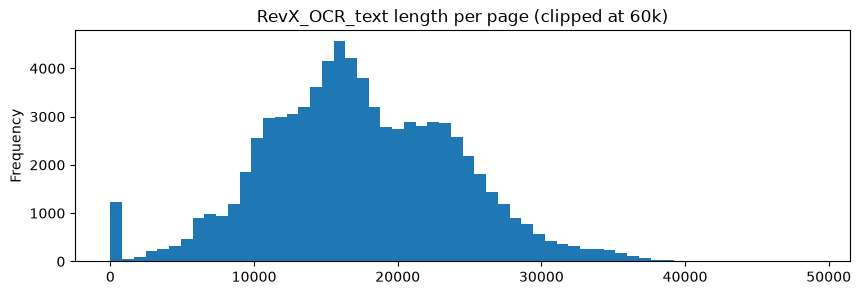

In [14]:
ax=q("select len_rx from news where len_rx is not null").len_rx.clip(upper=60000).plot(kind='hist',bins=60,figsize=(10,3),title='RevX_OCR_text length per page (clipped at 60k)')

In [15]:
# very short pages (probably blank / plates / failed OCR)
q("select count(*) pages_lt_500_chars_revx from news where len_rx<500"), q("select yr, count(*) n from news where len_rx<500 group by 1 order by 1 limit 12")

(   pages_lt_500_chars_revx
 0                     1229,
       yr   n
 0   1770   6
 1   1771   8
 2   1772   3
 3   1773   8
 4   1774  20
 5   1775   4
 6   1776   1
 7   1777   2
 8   1778   5
 9   1779   6
 10  1780   6
 11  1781   5)

## 6. Page and edition

In [16]:
print(q("select Page, count(*) n from news group by 1 order by 1").T)
q("select edition_order, count(*) n from news group by 1 order by 1")

         0      1      2      3    4    5    6    7   8   9   10  11  12  13  14  15  16
Page      1      2      3      4    5    6    7    8   9  10  11  12  13  14  15  16  17
n     19444  19390  18771  18740  578  520  137  128  17  17  16  16  10   5   2   1   1


,edition_order,n
0,1,76952
1,2,836
2,3,1
3,6,4


## 7. Native-term pages by year
Term list: prototype 2 `native` regex (`prototypes/code/02-migration-land/query.sql` line 56), the only Native list in `prototypes/`. It is narrow (land-cession phrases). Two broader generic lists (`broad` incl. words that are also places/surnames, `strict` without them) is added for comparison; both are regex on page text, **not** classification.

,yr,pages,proto_pages,protowb_pages,broad_pages,strict_pages,proto_pct,protowb_pct,broad_pct,strict_pct
0,1770,448,69.0,0.0,121.0,69.0,15.40,0.00,27.0,15.4
1,1771,546,74.0,8.0,198.0,131.0,13.55,1.47,36.3,24.0
2,1772,675,99.0,10.0,277.0,152.0,14.67,1.48,41.0,22.5
3,1773,846,110.0,11.0,420.0,258.0,13.00,1.30,49.6,30.5
4,1774,1205,217.0,18.0,600.0,379.0,18.01,1.49,49.8,31.5
5,1775,1286,189.0,21.0,679.0,493.0,14.70,1.63,52.8,38.3
6,1776,2319,223.0,10.0,1134.0,670.0,9.62,0.43,48.9,28.9
7,1777,1320,64.0,6.0,721.0,356.0,4.85,0.45,54.6,27.0
8,1778,970,109.0,7.0,471.0,261.0,11.24,0.72,48.6,26.9
9,1779,1660,152.0,5.0,921.0,534.0,9.16,0.30,55.5,32.2


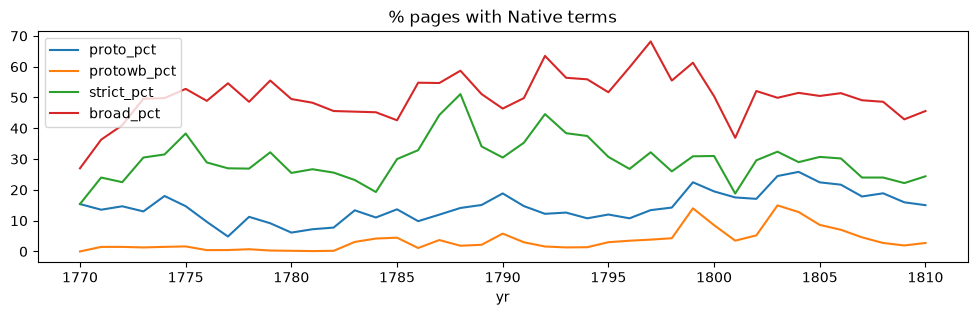

In [17]:
NATIVE_PROTO=r"indian (?:title|claim|lands?|boundary|purchase|treaty)|lands? (?:lately )?ceded|purchased of the indians|treaty of greenville|cession"
NATIVE_PROTO_WB=NATIVE_PROTO.replace("|cession",r"|\bcession\b")  # prototype list with a word boundary: plain "cession" also matches concession/succession
NATIVE_BROAD=r"\bindians?\b|\bcherokees?\b|\bchickasaws?\b|\bchoctaws?\b|\bcreeks?\b|\bshawan(?:ese|oes)\b|\bshawnees?\b|\bdelawares?\b|\bmiamis?\b|\biroquois\b|\bsix nations\b|\bseneca\b|\bmohawks?\b|\bwyandots?\b|\bpotawatom(?:ies|i)\b|\bmuskingum\b"
NATIVE_STRICT=r"\bindians?\b|\bcherokees?\b|\bchickasaws?\b|\bchoctaws?\b|\bshawan(?:ese|oes)\b|\bshawnees?\b|\biroquois\b|\bsix nations\b|\bmohawks?\b|\bwyandots?\b|\bpotawatom(?:ies|i)\b"  # broad minus delaware/creek/miami/seneca/muskingum (place or surname collisions)
con.execute("create or replace table nat as select yr, lower(coalesce(nullif(RevX_OCR_text,''),ca_ocr_text,'')) t from news")
nat=q(f"""select yr, count(*) pages,
 sum(regexp_matches(t,'{NATIVE_PROTO}')::int) proto_pages, sum(regexp_matches(t,'{NATIVE_PROTO_WB}')::int) protowb_pages,
 sum(regexp_matches(t,'{NATIVE_BROAD}')::int) broad_pages, sum(regexp_matches(t,'{NATIVE_STRICT}')::int) strict_pages from nat group by 1 order by 1""")
nat['proto_pct']=(100*nat.proto_pages/nat.pages).round(2); nat['protowb_pct']=(100*nat.protowb_pages/nat.pages).round(2); nat['broad_pct']=(100*nat.broad_pages/nat.pages).round(1); nat['strict_pct']=(100*nat.strict_pages/nat.pages).round(1)
display(nat); nat.set_index('yr')[['proto_pct','protowb_pct','strict_pct','broad_pct']].plot(figsize=(12,3),title='% pages with Native terms');

In [18]:
# false-positive eyeballing: 'creek', 'delaware', 'miami' are also places/rivers/state names; 'cession' is also generic
for term in ['creek','delaware','miami','cession','seneca']:
    r=q(f"select count(*) n from nat where regexp_matches(t,'\\b{term}s?\\b')").n[0]; print(term, r)
q(f"""select yr, regexp_extract(t,'((?s).{{0,60}}(?:{NATIVE_PROTO}).{{0,60}})',1) snippet from (select * from nat where regexp_matches(t,'{NATIVE_PROTO}') order by hash(t) limit 8)""")

creek 17934


delaware 11137


miami 1974


cession 2399


seneca 878


,yr,snippet
0,1805,"within three of their batteries; every one of which, in succession, were silenced so ..."
1,1801,has no views of that nature; for they demand no further concession than what were pre...
2,1806,have been alarmed for some time by all sorts of reports of cession or exchange of the...
3,1804,"arched or recruited within the state of georgia, and on the indian boundary between ge..."
4,1774,"bitants of the said province of canada, under grants and concessions from the governme..."
5,1791,"sh, with exceptions only of the rights saved by the deed of cession of virginia, and o..."
6,1807,"uld remain immovable; and that there must be some mutual concessions, and that he stil..."
7,1810,n to the federal government. we have been favored with a succession of wise and uprigh...


## 8. Assertions

In [19]:
r=q("select count(*) n, min(issue_date) mn, max(issue_date) mx from news").iloc[0]
assert r.n==12966+12966+12966+12965+12965+12965==77793, r.n          # MANIFEST + DATA.md
assert r.mn.year>=1770 and r.mx.year<=1810
assert q("select count(*) n from news where lccn is null or issue_date is null").n[0]==0
assert q("select count(*) n from news where edition_order is null").n[0]==0
def vs_docs(name, actual, documented):
    print(f"{'OK      ' if actual==documented else 'DIFFERS '} {name}: data={actual:,} DATA.md={documented:,}")
vs_docs('titles (lccn)', q("select count(distinct lccn) n from news").n[0], 105)
vs_docs('distinct newspaper_title strings', q("select count(distinct newspaper_title) n from news").n[0], 105)
vs_docs('places', q("select count(distinct place_of_publication) n from news").n[0], 48)
vs_docs('issues (lccn,date,edition)', q("select count(distinct (lccn,issue_date,edition_order)) n from news").n[0], 19445)
vs_docs('issues (lccn,date)', q("select count(distinct (lccn,issue_date)) n from news").n[0], 19445)
vs_docs('pages 1770-74', q("select count(*) n from news where yr between 1770 and 1774").n[0], 2600)
assert nat.proto_pages.sum()>0 and nat.broad_pages.sum()>=nat.proto_pages.sum()*0.5
print('assertions passed')

DIFFERS  titles (lccn): data=110 DATA.md=105
OK       distinct newspaper_title strings: data=105 DATA.md=105
OK       places: data=48 DATA.md=48
OK       issues (lccn,date,edition): data=19,445 DATA.md=19,445
DIFFERS  issues (lccn,date): data=19,303 DATA.md=19,445
DIFFERS  pages 1770-74: data=3,720 DATA.md=2,600
assertions passed


## 9. Findings
1. **Size.** 77,793 pages, 19,445 issues (lccn+date+edition), 48 place strings, 105 title strings, 1770-01-05 to 1810-12-31. Row count matches MANIFEST. Core fields (lccn, title, place, date, edition, Page) have 0 nulls.
2. **Skew to the 1800s.** Pages per year rise from 448 (1770) to ~4,000+ (1806-09). A gap in 1784-86 (356-644 pages/yr, only 2 titles). 1770-74 has 3,720 pages, not ~2,600 as DATA.md says.
3. **Titles are not 105.** There are **110 lccns** (105 distinct `newspaper_title` strings; some lccns share a title string or vice versa). Join on `lccn`, not title. Place strings vary in format for the same town ("Portsmouth [N.H.]" vs "Portsmouth, N.H."; 48 strings for fewer towns), so clean before grouping by place.
4. **Issues.** 19,445 holds only for (lccn, date, **edition_order**); on (lccn, date) alone it is 19,303. 841 pages are edition 2 or later (836 are edition 2).
5. **OCR mix.** `ca_ocr_text` is present on 99.99% of pages; `RevX_OCR_text` is null on 266 and blank on 1,216 more (~1.9% of pages unusable from RevX; 96-99% coverage by year, lowest 1797-99 and 1807-09). Median length is similar (RevX 16,951 chars vs ca 18,269), but the per-page ratio ranges 0.53-1.14 (p05-p95), so the two are not interchangeable. 1,229 pages have <500 chars of RevX text (plates, blanks, failures).
6. **Pages.** 4-page issues dominate; Page runs 1-17 (pages 5+ are only ~1.4k rows).
7. **Native terms (regex, page level, not classified).** The prototype list matches 5-26% of pages, but this is inflated: bare `cession` matches *concession/succession/secession*. With a word boundary the prototype list drops to ~0-2% most years, with a real bump 1799-1806 (peak 1803 at 15%; this is probably the Louisiana *cession* and Treaty of Greenville era, not necessarily Native land: check snippets). Generic words (`indian`, tribe names) hit 15-51% of pages (strict list) ('Indian corn', 'Indian trade', etc.). Treat all as candidate filters needing review, not counts of Native-land content.
8. **Reading caution.** `creek`, `delaware` (state/river/county), `miami`, `seneca` are place or surname collisions: excluded in the `strict` list.

**Contradicts DATA.md:** 105 titles (data: 110 lccns), 19,445 issues (only with edition), ~2,600 pages 1770-74 (data: 3,720). Row count, 48 places match.